#**Skew-T Log-P**
##⛅ Análise Termodinâmica de sondagem vertical da atmosfera


**INSTRUÇÕES DE USO DO SCRIPT: DIAGRAMA SKEW-T LOG-P**

**1º DEFINIÇÃO DOS PARÂMETROS DA SONDAGEM (INPUTS)**

✔ a) **Fonte de Dados**: Os perfis verticais são extraídos, decodificados e processados de forma 100% automatizada diretamente do repositório IGRA v2 (NOAA) < https://www.ncei.noaa.gov/pub/data/igra/data/ >. Não há necessidade de download de arquivos externos.

✔ b) **Data e Hora**: Na célula de extração (Parte 2), insira a data da análise alterando as variáveis de ano, mês e dia. Defina a hora sinótica desejada (00 ou 12).

✔ c) **Seleção da Estação**: Altere a variável estação teste inserindo o ID correspondente à localidade que deseja analisar. Utilize a tabela de referência abaixo:
•	Florianópolis (SC):  BRM00083899
•	Curitiba (PR):       BRM00083840
•	Foz do Iguaçu (PR):  BRM00083827
•	Londrina (PR):       BRM00083768
•	Santa Maria (RS):    BRM00083937
•	Campo Grande (MS):   BRM00083612
•	São Paulo/Marte (SP):BRM00083779
•	Buenos Aires (ARG):  ARM00087585
•	Resistência (ARG):   ARM00087155

**2º PROCESSAMENTO E EXECUÇÃO**

✔ a) **Execução Sequencial**: ▶ Execute as células em ordem, de cima para baixo.

✔ b) **Extração In-Memory**: A Parte 2 acessará o servidor, isolará a sondagem e construirá a matriz termodinâmica silenciosamente. Caso não haja dados para a data/hora solicitada (possível latência do servidor), um aviso de [FALHA] será emitido. Neste caso, interrompa a execução.

✔ c) **Análise**: Se o aviso for [SUCESSO], continue executando as células seguintes para que a matemática de instabilidade seja calculada e o gráfico seja gerado.

**3º EXPORTAÇÃO DO DIAGRAMA**

✔ a) **Salvamento Automático**: A penúltima célula salva a imagem em alta resolução no ambiente virtual, construindo o nome do arquivo dinamicamente com base nos metadados (Estação_Data_Hora).

✔ b) **Download**: Ao executar a última célula, o gráfico .jpg será baixado automaticamente para o computador local.
..-....

In [ ]:
#=============================================================================
# Parte 1: Importação de Bibliotecas e Inicialização do MetPy.
#=============================================================================
# Instalação e importação das bibliotecas Python necessárias para todo o
# processo de análise e visualização dos dados da radiossondagem final.
#----------------------------------------------------------------------------
#⛔ NÃO Altere! ▶ Execute!

import pandas as pd
import requests
import numpy as np
import zipfile
import io
import datetime
import matplotlib.pyplot as plt

!pip install metpy
from metpy.calc import lcl, parcel_profile
import metpy.calc as mpcalc
from metpy.plots import SkewT
from metpy.units import units
plt.show()

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 424.4/424.4 kB 8.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 307.5/307.5 kB 25.6 MB/s eta 0:00:00


In [ ]:
# ==============================================================================
# PARTE 2: EXTRAÇÃO AUTOMATIZADA E PARSER DE DADOS (NOAA IGRA v2)
# ==============================================================================
#
# Lógica Operacional:
# 1. Conexão e Identificação Institucional: Conecta ao repositório IGRA v2
#    (Year-to-Date ou Histórico) utilizando um 'User-Agent' acadêmico rastreável.
#    Essa transparência garante o consumo ético de dados governamentais e
#    previne bloqueios de firewall (anti-DDoS) aplicados a robôs anônimos.
# 2. Processamento in-memory: Realiza o download e a descompactação do arquivo
#    .zip estritamente na memória RAM, eliminando gargalos de I/O em disco.
# 3. Fatiamento Posicional (Fixed-Width): Localiza o cabeçalho da sondagem alvo
#    e extrai as variáveis termodinâmicas através de índices de caracteres
#    estritos, conforme documentação oficial do NOAA.
# 4. Tratamento Físico: Converte as escalas do IGRA (ex: pressão dividida por
#    100, temperatura por 10), calcula o Ponto de Orvalho (Td) e expurga níveis
#    com dados corrompidos ou ausentes (-9999).
# 5. Saída: Retorna um pandas DataFrame padronizado e um dicionário de metadados
#    prontos para injeção direta no motor de cálculo do MetPy.
# ==============================================================================
# ⛔ NÃO Altere! ▶ Execute!

# função obter_perfil_igra que busca dados meteorológicos da estação no banco de dados IGRA
def obter_perfil_igra(id_estacao: str, ano: int, mes: int, dia: int, hora: int) -> pd.DataFrame:
    ano_atual = datetime.datetime.now().year

    if ano == ano_atual:
        diretorio = "data-y2d"
        nome_base = f"{id_estacao}-data-beg{ano_atual}.txt"
    else:
        diretorio = "data-por"
        nome_base = f"{id_estacao}-data.txt"

    url = f"https://www.ncei.noaa.gov/pub/data/igra/data/{diretorio}/{nome_base}.zip"


# Substitua o dicionário 'headers' dentro da função obter_perfil_igra por este:

    headers = {
        'User-Agent': 'ProjetoRadiossondagem-IFSC-Agmatica/1.0 (jose.f1961@aluno.ifsc.edu.br; jlafigueiredo2@gmail.com)'
    }

    try:
        resposta = requests.get(url, headers=headers, timeout=15)
        resposta.raise_for_status()

        with zipfile.ZipFile(io.BytesIO(resposta.content)) as z:
            nome_interno = z.namelist()[0]
            with z.open(nome_interno) as f:
                texto_bruto = f.read().decode('utf-8')

    except Exception as e:
        print(f"Falha ao obter os dados: {e}")
        return pd.DataFrame()

    linhas = texto_bruto.splitlines()
    registros = []
    coletando = False

    cabecalho_alvo = f"#{id_estacao} {ano:04d} {mes:02d} {dia:02d} {hora:02d}"

    for linha in linhas:
        if linha.startswith('#'):
            if cabecalho_alvo in linha:
                coletando = True
                continue
            else:
                if coletando:
                    break
                coletando = False
                continue

        if coletando:
            try:
                # FATIAMENTO CORRIGIDO (Índices exatos do IGRA v2)
                pressao_str = linha[9:15].strip()
                temp_str = linha[22:27].strip()
                dpdp_str = linha[34:39].strip()
                wdir_str = linha[40:45].strip()
                wspd_str = linha[46:51].strip()

                pressao = float(pressao_str) / 100.0 if pressao_str != '-9999' else np.nan
                temp = float(temp_str) / 10.0 if temp_str != '-9999' else np.nan
                dpdp = float(dpdp_str) / 10.0 if dpdp_str != '-9999' else np.nan
                direcao = float(wdir_str) if wdir_str != '-9999' else np.nan
                velocidade = float(wspd_str) / 10.0 if wspd_str != '-9999' else np.nan

                dewpoint = temp - dpdp if pd.notna(temp) and pd.notna(dpdp) else np.nan
                registros.append([pressao, temp, dewpoint, direcao, velocidade])

            except ValueError:
                continue

    colunas = ["pressure", "temperature", "dewpoint", "direction", "speed"]
    df_temp = pd.DataFrame(registros, columns=colunas)

    df_temp = df_temp.dropna(subset=["pressure", "temperature", "dewpoint"])
    df_temp = df_temp.drop_duplicates(subset="pressure").sort_values("pressure", ascending=False).reset_index(drop=True)

    return df_temp

# --- Execução do Teste Unitário ---
estacao_teste = "BRM00083899"
ano_teste = 2026
mes_teste = 7
dia_teste = 29
hora_teste = 0

print(f"Interceptando IGRA v2: {estacao_teste} - {dia_teste:02d}/{mes_teste:02d}/{ano_teste} {hora_teste:02d}Z...")

df = obter_perfil_igra(estacao_teste, ano_teste, mes_teste, dia_teste, hora_teste)

# ==============================================================================
# @title 1º DEFINIÇÃO DOS PARÂMETROS DA SONDAGEM
# @markdown Selecione a estação e a data sinótica para extração no IGRA v2.
# ==============================================================================

Estacao = "BRM00083899 - Florianopolis (SC)" # @param ["BRM00083899 - Florianopolis (SC)", "BRM00083840 - Curitiba (PR)", "BRM00083827 - Foz do Iguacu (PR)", "BRM00083768 - Londrina (PR)", "BRM00083937 - Santa Maria (RS)", "BRM00083612 - Campo Grande (MS)", "BRM00083779 - Sao Paulo/Marte (SP)", "ARM00087585 - Buenos Aires (ARG)", "ARM00087155 - Resistencia (ARG)"]
Ano = 2026 # @param {type:"integer"}
Mes = 8 # @param {type:"integer"}
Dia = 20 # @param {type:"integer"}
Hora_Z = "12" # @param ["00", "12"]

# Extraindo os valores da interface
estacao_teste = Estacao.split(" - ")[0]
nome_local = Estacao.split(" - ")[1]
ano_teste = Ano
mes_teste = Mes
dia_teste = Dia
hora_teste = int(Hora_Z)

print(f"Interceptando IGRA v2: {estacao_teste} - {dia_teste:02d}/{mes_teste:02d}/{ano_teste} {hora_teste:02d}Z...")

# Acionando o motor de extração
df = obter_perfil_igra(estacao_teste, ano_teste, mes_teste, dia_teste, hora_teste)

if not df.empty:
    print(f"\n[SUCESSO] Sondagem lida: {len(df)} níveis termodinâmicos válidos.")
    print(f"Limites de pressão: de {df['pressure'].max():.0f} hPa a {df['pressure'].min():.0f} hPa.\n")

    # Metadados atualizados para o rodapé do Skew-T
    metadata_sondagem = {
        'Estacao': estacao_teste,
        'Hora_UTC': f"{hora_teste:02d} UTC",
        'Data': f"{dia_teste:02d}/{mes_teste:02d}/{ano_teste}",
        'Local': nome_local,
        'Fonte': 'NOAA IGRA v2'
    }
    print("-> Extração foi correta! Pode executar as próximas células de análise.")
else:
    print("\n[FALHA] Retorno vazio. A sondagem não está disponível no repositório para esta data/hora.")


Interceptando IGRA v2: BRM00083899 - 29/07/2026 00Z...
Interceptando IGRA v2: BRM00083899 - 20/08/2026 12Z...

[SUCESSO] Sondagem lida: 63 níveis termodinâmicos válidos.
Limites de pressão: de 1016 hPa a 13 hPa.

-> Extração foi correta! Pode executar as próximas células de análise.


In [ ]:
#===============================================================================
# Parte 3: Cálculo Analítico (Níveis Especiais e Índices de Instabilidade).
#===============================================================================
#CALCULA OS NÍVEIS ESPECIAIS E OS ÍNDICES DE INSTABILIDADE
#Esta célula introduz a seção de cálculo de índices e níveis especiais.
#Ela explica os conceitos teóricos fundamentais (Teoria da Parcela, Gradientes
#Adiabáticos, Flutuabilidade) que embasam os cálculos realizados pela biblioteca
#MetPy.
#-------------------------------------------------------------------------------
#⛔ NÃO Altere! ▶ Execute!

def analisar(df: pd.DataFrame) -> dict:
    p = df["pressure"].values * units.hPa
    T = df["temperature"].values * units.degC
    Td = df["dewpoint"].values * units.degC

    resultados = {}

    perfil_parcela = mpcalc.parcel_profile(p, T[0], Td[0]).to("degC")

    # Calcula CAPE / CINE
    cape, cine = mpcalc.cape_cin(p, T, Td, perfil_parcela)
    resultados["CAPE"] = cape
    resultados["CINE"] = cine

    # Calcula NCL
    p_ncl, T_ncl = mpcalc.lcl(p[0], T[0], Td[0])
    resultados["NCL_pressao"] = p_ncl
    resultados["NCL_temperatura"] = T_ncl

    # Calcula NE
    try:
        p_ne, T_ne = mpcalc.el(p, T, Td, perfil_parcela)
        resultados["NE_pressao"] = p_ne
        resultados["NE_temperatura"] = T_ne
    except Exception:
        resultados["NE_pressao"] = None
        resultados["NE_temperatura"] = None

    # Calcula NCC e TC
    try:
        p_ncc, T_ncc, T_c = mpcalc.ccl(p, T, Td)
        resultados["NCC_pressao"] = p_ncc
        resultados["NCC_temperatura"] = T_ncc
        resultados["TC"] = T_c
    except Exception:
        resultados["NCC_pressao"] = None
        resultados["NCC_temperatura"] = None
        resultados["TC"] = None

    # Calcula Índices clássicos (fórmulas fechadas)
    def _t_td_em(nivel_hpa):
        i = int(np.argmin(np.abs(p.m - nivel_hpa)))
        return T[i], Td[i]

    # Calcula T e Td (850, 700 e 500 hPa).
    T850, Td850 = _t_td_em(850)
    T700, Td700 = _t_td_em(700)
    T500, Td500 = _t_td_em(500)

    # Converte valores em °C.
    t850, td850 = T850.m, Td850.m
    t700, td700 = T700.m, Td700.m
    t500 = T500.m

    # Calcula Índice K
    resultados["K_index"] = (t850 - t500) + td850 - (t700 - td700)

    # Calcula Totals Totals
    resultados["Totals_Totals"] = (t850 + td850) - 2 * t500

    # Calcula Showalter Index (de 850 hPa até 500 hPa).
    # Indica o potencial de convecção.
    p_850_a_topo = p[p.m <= 850] # Filtra pressões de 850 hPa para cima.
    perfil_850 = mpcalc.parcel_profile(p_850_a_topo, T850, Td850).to("degC") # Calcula o perfil da parcela a partir de 850 hPa.
    idx_500_no_recorte = int(np.argmin(np.abs(p_850_a_topo.m - 500))) # Encontra o índice de 500 hPa no perfil recortado.
    T_parcela_500_showalter = perfil_850[idx_500_no_recorte] # Temperatura da parcela em 500 hPa.
    resultados["Showalter"] = t500 - T_parcela_500_showalter.m # Showalter = T_ambiente_500 - T_parcela_500.

    # Calcula Lifted Index (da superfície até 500 hPa).
    T_parcela_500_lifted = perfil_parcela[np.argmin(np.abs(p.m - 500))]
    resultados["Lifted_Index"] = t500 - T_parcela_500_lifted.m # Lifted Index = T_ambiente_500 - T_parcela_500.

    # Calcula SWEAT (precisa de vento em 850 e 500 hPa)
    if df["direction"].notna().any() and df["speed"].notna().any():
        # Verifica se há dados de vento disponíveis.
        i850 = int(np.argmin(np.abs(p.m - 850)))
        i500 = int(np.argmin(np.abs(p.m - 500)))
        dd850, ff850 = df["direction"][i850], df["speed"][i850]
        dd500, ff500 = df["direction"][i500], df["speed"][i500]
        # Calcula SWEAT se os dados de vento necessários não forem NaN.
        if not (np.isnan(dd850) or np.isnan(ff850) or np.isnan(dd500) or np.isnan(ff500)):
            TT = resultados["Totals_Totals"]
            cisalhamento = np.sin(np.radians(dd500 - dd850)) # Cisalhamento vertical do vento.
            # Termo direcional, uma componente do SWEAT que considera a direção do vento.
            termo_direcional = 125 * (cisalhamento + 0.2) if (
                130 <= dd850 <= 250 and 210 <= dd500 <= 310
                and (dd500 - dd850) > 0 and ff850 >= 15 and ff500 >= 15
            ) else 0
            # Fórmula completa do SWEAT.
            sweat = (12 * max(td850, 0) + 20 * max(TT - 49, 0)
                     + 2 * ff850 + ff500 + termo_direcional)
            resultados["SWEAT"] = sweat
        else:
            resultados["SWEAT"] = None # None (ausência de valor)
    else:
        resultados["SWEAT"] = None # None (ausência de valor)

    # Armazena os perfis originais e o perfil da parcela no dicionário de resultados.
    resultados["_p"], resultados["_T"], resultados["_Td"] = p, T, Td
    resultados["_perfil_parcela"] = perfil_parcela
    # Retorna o dicionário com todos os resultados.
    return resultados

# Analisa DataFrame e armazena os resultados.
r = analisar(df)

print("Índices calculados!")
plt.show()

Índices calculados!


In [ ]:
import matplotlib.pyplot as plt

#===============================================================================
# Parte 4: Relatório Textual dos Resultados Termodinâmicos.
#===============================================================================
# GERA O RELATÓRIO DOS NÍVEIS ESPECIAIS E ÍNDICES DE INSTABILIDADE
# Esta célula gerará um relatório textual com os valores calculados dos índices
# de instabilidade e níveis especiais, utilizando os dados da radiossondagem.
#-------------------------------------------------------------------------------
#⛔ NÃO Altere! ▶ Execute!

# Função pressão.
def fmt_p(v):
    return "—" if v is None else f"{v.m:.0f} hPa"

# Função temperatura.
def fmt_t(v):
    return "—" if v is None else f"{v.m:.1f} °C"

# Função genérica números.
def fmt_n(v, casas=1, unidade=""):
    return "—" if v is None else f"{v:.{casas}f}{unidade}"

# Verifica definição 'r' e dados.
if 'r' not in globals() or not r:
    print("============================================================")
    print("NÃO HÁ DADOS DISPONÍVEIS PARA GERAR O RELATÓRIO.")
    print("Por favor, verifique se a extração de dados na Parte 2 foi bem-sucedida.")
    print("============================================================")
else:
    # Formatação do layout do relatório
    print("=" * 60)
    print("RELATÓRIO DOS ÍNDICES DE INSTABILIDADE")
    print("=" * 60)
    print("NÍVEIS ESPECIAIS")
    print("=" * 60)
    print("=" * 60)
    print(f"NCL  — P={fmt_p(r['NCL_pressao'])}   T={fmt_t(r['NCL_temperatura'])}")
    print(f"NCC  — P={fmt_p(r['NCC_pressao'])}   T={fmt_t(r['NCC_temperatura'])}")
    print(f"TC                   {fmt_t(r['TC'])}")
    print(f"NE   — P={fmt_p(r['NE_pressao'])}   T={fmt_t(r['NE_temperatura'])}")
    print()
    print("=" * 60)
    print("ÍNDICES DE INSTABILIDADE")
    print("=" * 60)
    print(f"CAPE               {fmt_n(r['CAPE'].m, 0, ' J/kg')}")
    print(f"CINE               {fmt_n(r['CINE'].m, 0, ' J/kg')}")
    print(f"K Index            {fmt_n(r['K_index'], 1, ' °C')}")
    print(f"Totals Totals      {fmt_n(r['Totals_Totals'], 1, ' °C')}")
    print(f"Showalter Index    {fmt_n(r['Showalter'], 1, ' °C')}")
    print(f"Lifted Index       {fmt_n(r['Lifted_Index'], 1, ' °C')}")
    sweat_txt = fmt_n(r["SWEAT"], 0) if r["SWEAT"] is not None else "— (sem dado de vento em 850/500 hPa)"
    print(f"SWEAT              {sweat_txt}")

plt.show()

RELATÓRIO DOS ÍNDICES DE INSTABILIDADE
NÍVEIS ESPECIAIS
NCL  — P=994 hPa   T=18.5 °C
NCC  — P=797 hPa   T=15.1 °C
TC                   35.8 °C
NE   — P=509 hPa   T=-9.7 °C

ÍNDICES DE INSTABILIDADE
CAPE               8 J/kg
CINE               -368 J/kg
K Index            11.5 °C
Totals Totals      48.6 °C
Showalter Index    -0.6 °C
Lifted Index       0.5 °C
SWEAT              185


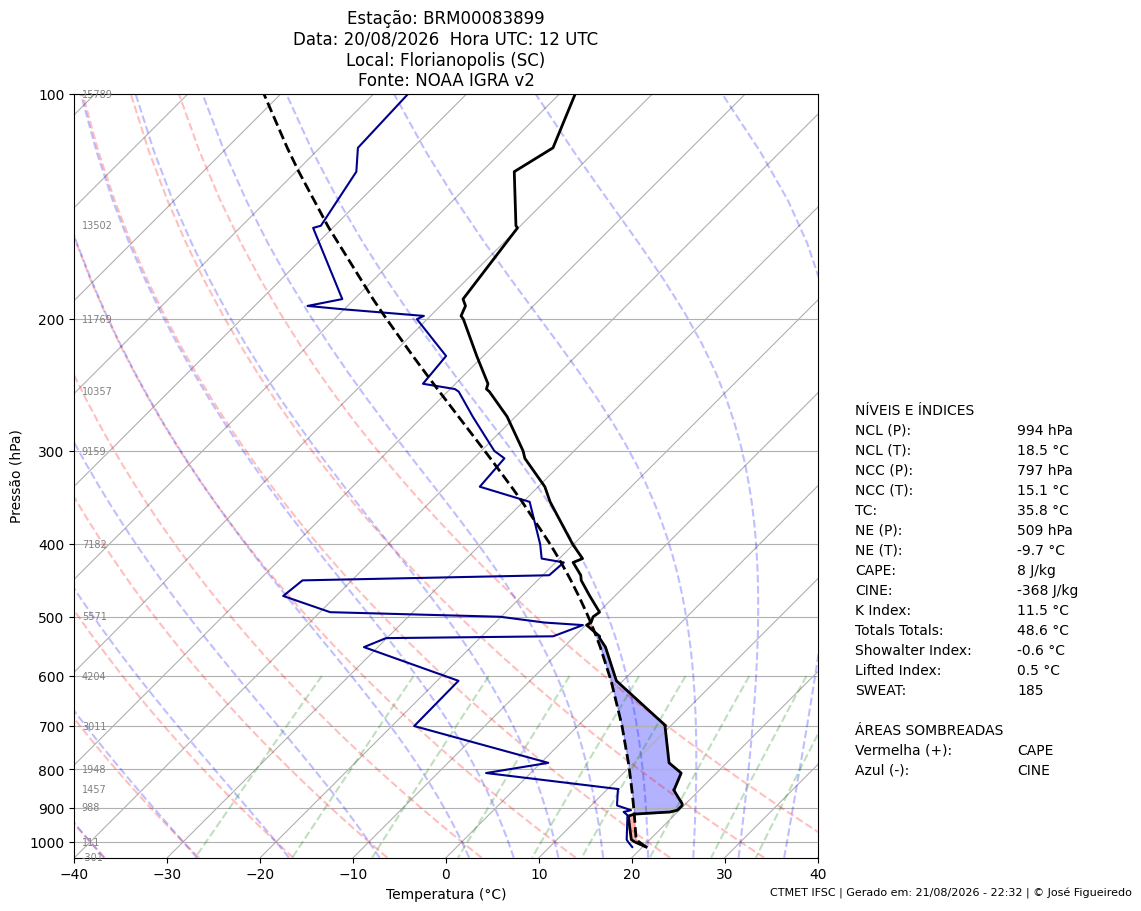

Figura salva como: BRM00083899_20082026_12UTC_skewt.jpg


In [ ]:
#==============================================================================
# Parte 5: Renderização do Diagrama Termodinâmico (Skew-T Log-P).
#==============================================================================
# Esta célula processa os dados para gerar o Diagrama Termodinâmico Skew-T log-P.
# Configura também as áreas que serão sombreadas no gráfico que reprentarão o
# CAPE e o CINE.
#------------------------------------------------------------------------------
#⛔ NÃO Altere! ▶ Execute!

import matplotlib.transforms as transforms

# Função para formatar valores de pressão.
def fmt_p(v):
    return "—" if v is None else f"{v.m:.0f} hPa"

# Função para formatar valores de temperatura.
def fmt_t(v):
    return "—" if v is None else f"{v.m:.1f} °C"

# Função formatar números.
def fmt_n(v, casas=1, unidade=""):
    return "—" if v is None else f"{v:.{casas}f}{unidade}"

# Verifica se 'r' e seus dados estão disponíveis
if 'r' not in globals() or not r or "_p" not in r or "_T" not in r or "_Td" not in r or "_perfil_parcela" not in r:
    print("============================================================")
    print("NÃO HÁ DADOS VÁLIDOS PARA RENDERIZAR O DIAGRAMA TERMÓDINAMICO.")
    print("Por favor, verifique se a extração de dados (Parte 2) e o cálculo dos índices (Parte 3) foram bem-sucedidos.")
    print("============================================================")
else:
    # Desempacota os dados de pressão, temperatura, ponto de orvalho e perfil da parcela dos resultados.
    p, T, Td, perfil = r["_p"], r["_T"], r["_Td"], r["_perfil_parcela"]

    # Cria figura para o gráfico.
    fig = plt.figure(figsize=(14, 9), layout="constrained")
    # Criar o diagrama termodinâmico.
    skew = SkewT(fig, rotation=45)

    # Plota a linha de temperatura (T).
    skew.plot(p, T, color="black", linewidth=2)
    # Plota a linha de ponto de orvalho (Td).
    skew.plot(p, Td, color="darkblue")     #, linewidth=2, label="Td")
    # Plota o perfil da parcela de ar.
    skew.plot(p, perfil, color="black", linewidth=2, linestyle="--")   #,label="Parcela")
    # Sombreado a área de CAPE.
    skew.shade_cape(p, T, perfil, color="red", alpha=0.3)
    # Sombreado a área de CINE.
    skew.shade_cin(p, T, perfil, Td, color="blue", alpha=0.3)

    # Define os limites do eixo X (temperatura) e Y (pressão)
    skew.ax.set_xlim(-40, 40)
    skew.ax.set_ylim(1050, 100)
    # Plota as adiabáticas secas.
    skew.plot_dry_adiabats(alpha=0.25)
    # Plota as adiabáticas úmidas.
    skew.plot_moist_adiabats(alpha=0.25)
    # Plota as linhas de razão de mistura.
    skew.plot_mixing_lines(alpha=0.25)
    # Rótulo do eixo X.
    skew.ax.set_xlabel("Temperatura (°C)")
    # Rótulo do eixo Y.
    skew.ax.set_ylabel("Pressão (hPa)")

    from datetime import datetime
    data_atual = datetime.now().strftime("%d/%m/%Y - %H:%M")
    BASEBOARD = f"CTMET IFSC | Gerado em: {data_atual} | \u00A9 José Figueiredo"

    transform_custom = transforms.blended_transform_factory(skew.ax.transAxes, skew.ax.transData)
    pressoes_grade = [100, 150, 200, 250, 300, 400, 500, 600, 700, 800, 850, 900, 1000, 1050]
    for pg in pressoes_grade:
        h = mpcalc.pressure_to_height_std(pg * units.hPa).to('m').m

        skew.ax.text(0.01, pg, f'{h:.0f}', fontsize=7, color='gray',
                     verticalalignment='center', horizontalalignment='left',
                     transform=transform_custom)

    # Título completo do gráfico usando os metadados da sondagem.
    titulo_completo = (
        f"Estação: {metadata_sondagem.get('Estacao', 'N/A')}\n"
        f"Data: {metadata_sondagem.get('Data', 'N/A')}  "
        f"Hora UTC: {metadata_sondagem.get('Hora_UTC', 'N/A')}\n"
        f"Local: {metadata_sondagem.get('Local', 'N/A')}\n"
        f"Fonte: {metadata_sondagem.get('Fonte', 'N/A')}"
    )
    # Define o título do gráfico.
    skew.ax.set_title(titulo_completo)

    # Preparar tabela lateral
    table_data = [
        ["NÍVEIS E ÍNDICES", ""],
        ["NCL (P):", fmt_p(r['NCL_pressao'])],
        ["NCL (T):", fmt_t(r['NCL_temperatura'])],
        ["NCC (P):", fmt_p(r['NCC_pressao'])],
        ["NCC (T):", fmt_t(r['NCC_temperatura'])],
        ["TC:", fmt_t(r['TC'])],
        ["NE (P):", fmt_p(r['NE_pressao'])],
        ["NE (T):", fmt_t(r['NE_temperatura'])],
        ["CAPE:", fmt_n(r['CAPE'].m, 0, ' J/kg')],
        ["CINE:", fmt_n(r['CINE'].m, 0, ' J/kg')],
        ["K Index:", fmt_n(r['K_index'], 1, ' °C')],
        ["Totals Totals:", fmt_n(r['Totals_Totals'], 1, ' °C')],
        ["Showalter Index:", fmt_n(r['Showalter'], 1, ' °C')],
        ["Lifted Index:", fmt_n(r['Lifted_Index'], 1, ' °C')],
        ["SWEAT:", fmt_n(r["SWEAT"], 0) if r["SWEAT"] is not None else "—"],
        ["", ""], # Linha separadora vazia na tabela.
        ["ÁREAS SOMBREADAS", ""],
        ["Vermelha (+):", "CAPE"],
        ["Azul (-):", "CINE"],
    ]

    # Cria tabela ao lado direito do gráfico
    table_ax = fig.add_axes([0.78, 0.1, 0.20, 0.5])
    table_ax.axis('off')
    tbl = table_ax.table(cellText=table_data,
                         cellLoc='left',
                         loc='center',
                         colWidths=[0.6, 0.4])

    # Desativa o ajuste automático e defina o tamanho da fonte.
    tbl.auto_set_font_size(False)
    tbl.set_fontsize(10)
    tbl.scale(1, 1.2)
    for key, cell in tbl.get_celld().items():
        cell.set_edgecolor('none')

    # Nome do arquivo de saída de forma dinâmica usando os metadados do IGRA
    str_data = metadata_sondagem['Data'].replace('/', '')
    str_hora = metadata_sondagem['Hora_UTC'].replace(' ', '')
    nome_saida = f"{metadata_sondagem['Estacao']}_{str_data}_{str_hora}_skewt.jpg"
    fig.text(0.99, 0.01, BASEBOARD, fontsize=8, ha='right')
    fig.savefig(nome_saida, dpi=150, bbox_inches="tight")

    plt.show()
    print(f"Figura salva como: {nome_saida}")

In [ ]:
#==============================================================================
# Parte 6: Exportação e Salvamento do Gráfico.
#=============================================================================
# Nesta célula permite ao usuário exportar o gráfico do Skew-T Log-P, extensão
# "jpg", direto para o seu computador, apenas NO ambiente do Google Colab.
#------------------------------------------------------------------------------
#⛔ NÃO Altere! ▶ Execute!

try:
    from google.colab import files
    files.download(nome_saida)
except ImportError:
    print("Fora do Colab — a figura já está salva localmente em:", nome_saida)
plt.show()

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Sempre restará muito a aprender**!

   A construção deste Diagrama Termodinâmico, fundamentado nas disciplinas de Termodinâmica da Atmosfera I e II, tornou-se real através dos conhecimentos que adquiri em Análise de Dados Meteorológicos (ADM11902) e Processamento de Dados Meteorológicos (PDM11901). Essas matérias foram a base para minha familiarização com a programação em Python e com a manipulação de dados brutos, permitindo criar um script versátil, capaz de processar informações de qualquer estação meteorológica do mundo para analisar índices e níveis termodinâmicos. No processo de refinamento e aperfeiçoamento do código, contei também com o suporte da Inteligência Artificial.
   
   José Figueiredo